In [1]:
!pip install -q xgboost

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from sklearn.utils.class_weight import compute_sample_weight

from xgboost import XGBClassifier

import joblib

print("Libraries imported successfully")

Libraries imported successfully


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
vehicle_path = "/content/drive/MyDrive/AutoSenseAI/data/vehicle_maintenance_data.csv"

df = pd.read_csv(vehicle_path)

df.head()

,Vehicle_Model,Mileage,Maintenance_History,Reported_Issues,Vehicle_Age,Fuel_Type,Transmission_Type,Engine_Size,Odometer_Reading,Last_Service_Date,Warranty_Expiry_Date,Owner_Type,Insurance_Premium,Service_History,Accident_History,Fuel_Efficiency,Tire_Condition,Brake_Condition,Battery_Status,Need_Maintenance
0,Truck,58765,Good,0,4,Electric,Automatic,2000,28524,2023-11-23,2025-06-24,Second,20782,6,3,13.622204,New,New,Weak,1
1,Van,60353,Average,1,7,Electric,Automatic,2500,133630,2023-09-21,2025-06-04,Second,23489,7,0,13.625307,New,New,Weak,1
2,Bus,68072,Poor,0,2,Electric,Automatic,1500,34022,2023-06-27,2025-04-27,First,17979,7,0,14.306302,New,Good,Weak,1
3,Bus,60849,Average,4,5,Petrol,Automatic,2500,81636,2023-08-24,2025-11-05,Second,6220,7,3,18.709467,New,Worn Out,New,1
4,Bus,45742,Poor,5,1,Petrol,Manual,2000,97162,2023-05-25,2025-09-14,Third,16446,6,2,16.977482,Good,Good,Weak,1


In [5]:
print("Dataset shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

Dataset shape: (50000, 20)

Columns:
['Vehicle_Model', 'Mileage', 'Maintenance_History', 'Reported_Issues', 'Vehicle_Age', 'Fuel_Type', 'Transmission_Type', 'Engine_Size', 'Odometer_Reading', 'Last_Service_Date', 'Warranty_Expiry_Date', 'Owner_Type', 'Insurance_Premium', 'Service_History', 'Accident_History', 'Fuel_Efficiency', 'Tire_Condition', 'Brake_Condition', 'Battery_Status', 'Need_Maintenance']

Data types:
Vehicle_Model            object
Mileage                   int64
Maintenance_History      object
Reported_Issues           int64
Vehicle_Age               int64
Fuel_Type                object
Transmission_Type        object
Engine_Size               int64
Odometer_Reading          int64
Last_Service_Date        object
Warranty_Expiry_Date     object
Owner_Type               object
Insurance_Premium         int64
Service_History           int64
Accident_History          int64
Fuel_Efficiency         float64
Tire_Condition           object
Brake_Condition          object
Batter

In [6]:
print(df["Need_Maintenance"].value_counts())

print(
    df["Need_Maintenance"]
    .value_counts(normalize=True)
    .mul(100)
)

Need_Maintenance
1    40498
0     9502
Name: count, dtype: int64
Need_Maintenance
1    80.996
0    19.004
Name: proportion, dtype: float64


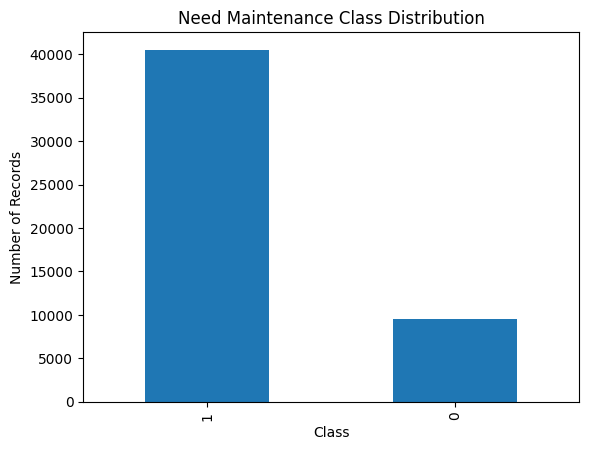

In [7]:
df["Need_Maintenance"].value_counts().plot(kind="bar")

plt.title("Need Maintenance Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Records")
plt.show()

In [8]:
target = "Need_Maintenance"

drop_columns = [
    "Need_Maintenance",
    "Last_Service_Date",
    "Warranty_Expiry_Date"
]

X = df.drop(columns=drop_columns)
y = df[target]

print("Input shape:", X.shape)
print("Target shape:", y.shape)

Input shape: (50000, 17)
Target shape: (50000,)


In [9]:
categorical_columns = X.select_dtypes(include=["object"]).columns.tolist()

numerical_columns = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

print("Categorical columns:")
print(categorical_columns)

print("\nNumerical columns:")
print(numerical_columns)

Categorical columns:
['Vehicle_Model', 'Maintenance_History', 'Fuel_Type', 'Transmission_Type', 'Owner_Type', 'Tire_Condition', 'Brake_Condition', 'Battery_Status']

Numerical columns:
['Mileage', 'Reported_Issues', 'Vehicle_Age', 'Engine_Size', 'Odometer_Reading', 'Insurance_Premium', 'Service_History', 'Accident_History', 'Fuel_Efficiency']


In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 40000
Testing samples: 10000


In [11]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_columns
        ),
        (
            "numerical",
            "passthrough",
            numerical_columns
        )
    ]
)

In [12]:
xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,

    objective="binary:logistic",
    eval_metric="logloss",

    random_state=42,
    n_jobs=-1
)

In [13]:
model_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", xgb_model)
    ]
)

In [14]:
sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train
)

In [15]:
model_pipeline.fit(
    X_train,
    y_train,
    classifier__sample_weight=sample_weights
)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('categorical',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Vehicle_Model',
                                                   'Maintenance_History',
                                                   'Fuel_Type',
                                                   'Transmission_Type',
                                                   'Owner_Type',
                                                   'Tire_Condition',
                                                   'Brake_Condition',
                                                   'Battery_Status']),
                                                 ('numerical', 'passthrough',
                                                  ['Mileage', 'Reported_Issues',
                                                   'Vehicle_Age', 'Engine_Size',
                                                   'Odometer_...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.05,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=5, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=300, n_jobs=-1,
                               num_parallel_tree=None, ...))])

In [16]:
y_pred = model_pipeline.predict(X_test)

In [17]:
y_probability = model_pipeline.predict_proba(X_test)[:, 1]

In [18]:
print(y_pred[:10])
print(y_probability[:10])

[1 0 1 1 1 1 1 0 1 1]
[9.9999714e-01 9.3567901e-04 9.9912888e-01 9.9986100e-01 9.9721956e-01
 9.9974269e-01 9.9998450e-01 6.6726898e-05 9.9987578e-01 9.9972075e-01]


In [19]:
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(y_test, y_pred)

recall = recall_score(y_test, y_pred)

f1 = f1_score(y_test, y_pred)

macro_f1 = f1_score(
    y_test,
    y_pred,
    average="macro"
)

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)
print("Macro F1 :", macro_f1)

Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1 Score : 1.0
Macro F1 : 1.0


In [20]:
print(
    classification_report(
        y_test,
        y_pred
    )
)

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1900
           1       1.00      1.00      1.00      8100

    accuracy                           1.00     10000
   macro avg       1.00      1.00      1.00     10000
weighted avg       1.00      1.00      1.00     10000



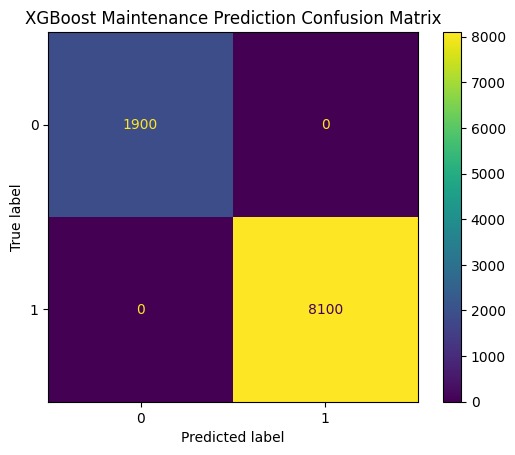

In [21]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred
)

plt.title("XGBoost Maintenance Prediction Confusion Matrix")
plt.show()

In [22]:
import os

model_dir = "/content/drive/MyDrive/AutoSenseAI/models"

os.makedirs(
    model_dir,
    exist_ok=True
)


In [23]:
joblib.dump(
    model_pipeline,
    model_dir + "/vehicle_maintenance_xgboost.pkl"
)

print("Model saved successfully")

Model saved successfully
